## ANN (Artifical Neural Networks)

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [10]:
data = load_breast_cancer()
x = data.data
y = data.target

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


In [11]:
model = Sequential()
model.add(Dense(16, activation='relu', input_shape=(30,))) # input layer
model.add(Dense(8, activation='relu')) # hidden layer
model.add(Dense(1, activation='sigmoid')) # output layer

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.callbacks import Callback

class WeightLogger(Callback):
    def on_epoch_end(self, epoch, logs = None):
        print(f'Epoch No.{epoch+1}')
        for i, layer in enumerate(self.model.layers):
            print(f'Layer No. {i+1}')
            w,b = layer.get_weights()
            print('Weights:', w)
            print('Bias:', b)

In [13]:
history = model.fit(x_train, y_train, batch_size=16, epochs=20, verbose=1, validation_split=0.2)
# add callbacks=[WeightLogger()] above to see the weights & bias of each layer
# if u keep increasing the epochs, better accuracy will come. But it's best to increase for complex data like images

y_pred_proba = model.predict(x_test)
y_pred = (y_pred_proba>0.5).astype(int).flatten()
print('Accuracy Score:', accuracy_score(y_test, y_pred))

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.7225 - loss: 0.5698 - val_accuracy: 0.8462 - val_loss: 0.4817
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8709 - loss: 0.3725 - val_accuracy: 0.9011 - val_loss: 0.3664
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9093 - loss: 0.2873 - val_accuracy: 0.9341 - val_loss: 0.2949
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9313 - loss: 0.2391 - val_accuracy: 0.9560 - val_loss: 0.2443
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9368 - loss: 0.2053 - val_accuracy: 0.9670 - val_loss: 0.2065
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9451 - loss: 0.1795 - val_accuracy: 0.9560 - val_loss: 0.1784
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9505 - loss: 0.1595 - val_accuracy: 0.9560 - val_loss: 0.1554
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9533 - loss: 0.1435 - val_accuracy: 0.9560 - v

In [14]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

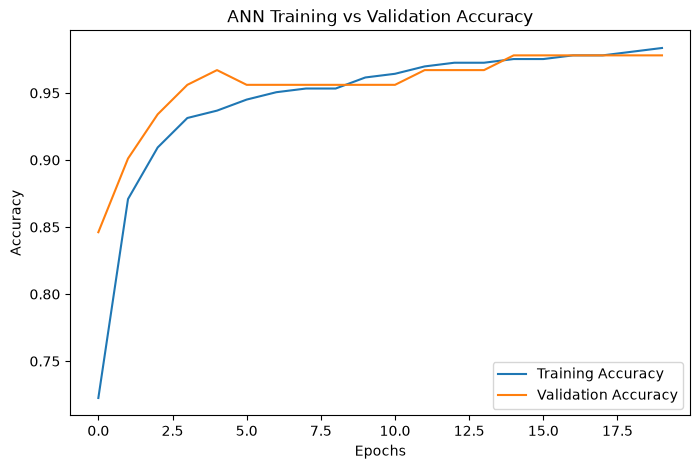

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ANN Training vs Validation Accuracy')
plt.legend()
plt.show()

After a certain No. of epochs, the Accuracy converges

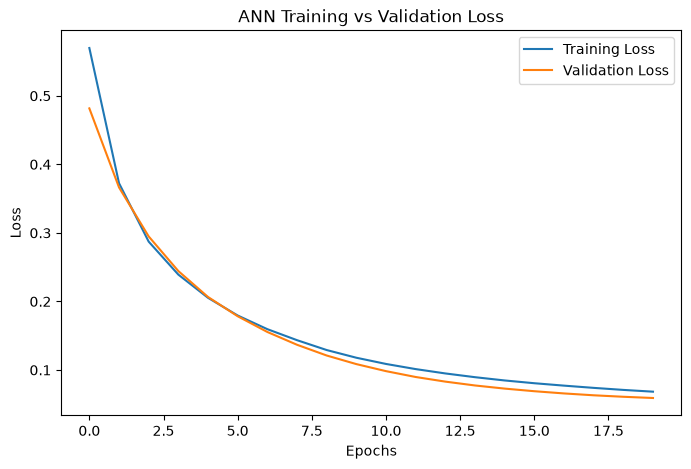

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('ANN Training vs Validation Loss')
plt.legend()
plt.show()

## Image Classification

### Handwritten Digits (0-9) Dataset

In [17]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

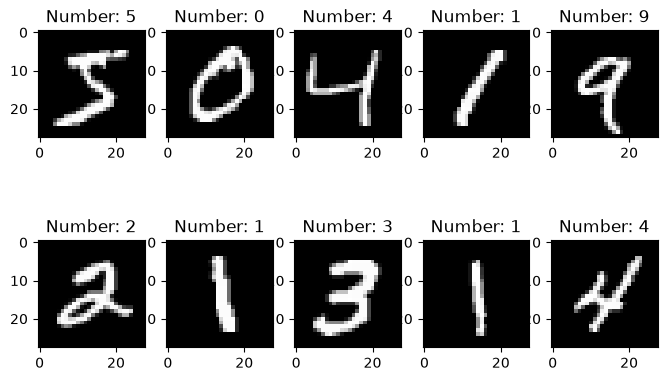

In [18]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

plt.figure(figsize=(8,5))
for i in range(10):
    plt.subplot(2,5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Number: {y_train[i]}')
plt.show()

In [19]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [20]:
# Need to convert to 1D array

x_train = x_train.reshape((60000, 784))
x_test = x_test.reshape((10000, 784))

# Need to normalize it

x_train = x_train/255
x_test = x_test/255

In [21]:
model = Sequential([Dense(128, activation='relu', input_shape=(784,)),
                    Dense(64, activation='relu'),
                    Dense(32, activation='relu'),
                    Dense(10, activation='softmax') # 10 because we have 10 digits (0-9) hence we will get the probabilty of the
                    ]) # digit belonging to each class - and softmax for multiclass classification

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(optimizer='sgd', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2, verbose=1)
test_loss, test_acc = model.evaluate(x_test, y_test)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.7943 - loss: 0.7280 - val_accuracy: 0.9054 - val_loss: 0.3294
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9120 - loss: 0.3015 - val_accuracy: 0.9251 - val_loss: 0.2540
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9297 - loss: 0.2391 - val_accuracy: 0.9378 - val_loss: 0.2151
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9423 - loss: 0.2001 - val_accuracy: 0.9461 - val_loss: 0.1881
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9506 - loss: 0.1716 - val_accuracy: 0.9518 - val_loss: 0.1682
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9564 - loss: 0.1500 - val_accuracy: 0.9561 - val_loss: 0.1535
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9616 - loss: 0.1326 - val_accuracy: 0.9589 - val_loss: 0.1425
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9659 - loss: 0.1185

In [23]:
y_pred_proba = model.predict(x_test)
y_pred = np.argmax(y_pred_proba, axis=1)
print('Accuracy Score:', accuracy_score(y_test, y_pred))
print('Loss:', test_loss)

 40/313 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step
Accuracy Score: 0.9644
Loss: 0.11526068300008774


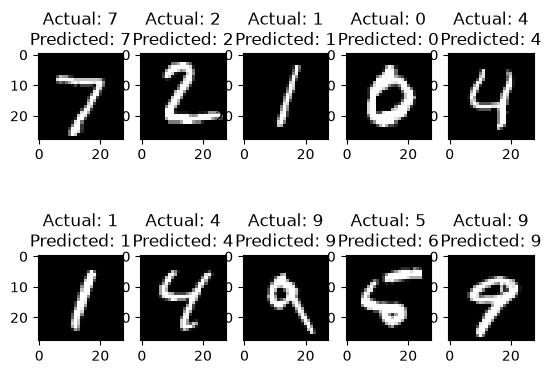

In [24]:
(x_train,y_train),(x_test,y_test)=mnist.load_data()
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i],cmap="gray")
    plt.title(f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}")
plt.show()


### Fashion Images Dataset

In [25]:
from tensorflow.keras.datasets import fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

In [26]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


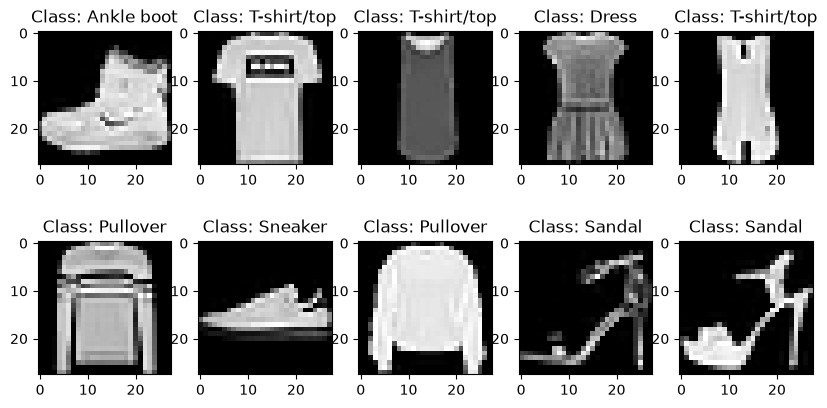

In [37]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Class: {class_names[y_train[i]]}')

plt.show()

In [27]:
from tensorflow.keras.layers import Flatten

x_train = x_train/255
x_test = x_test/255

model = Sequential([Flatten(input_shape=(28,28)),
                    Dense(128, activation='relu'),
                    Dense(64, activation='relu'),
                    Dense(32, activation='relu'),
                    Dense(10, activation='softmax')
                    ])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=20, batch_size=32 ,validation_split=0.2 ,verbose=1)
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Loss :",test_loss)
print("Accuracy :",test_accuracy)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.8126 - loss: 0.5300 - val_accuracy: 0.8116 - val_loss: 0.4919
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8599 - loss: 0.3824 - val_accuracy: 0.8407 - val_loss: 0.4228
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8727 - loss: 0.3448 - val_accuracy: 0.8377 - val_loss: 0.4357
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8806 - loss: 0.3189 - val_accuracy: 0.8571 - val_loss: 0.3900
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8883 - loss: 0.2988 - val_accuracy: 0.8658 - val_loss: 0.3719
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8950 - loss: 0.2822 - val_accuracy: 0.8627 - val_loss: 0.3831
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8992 - loss: 0.2710 - val_accuracy: 0.8688 - val_loss: 0.3731
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9036 - loss: 0

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


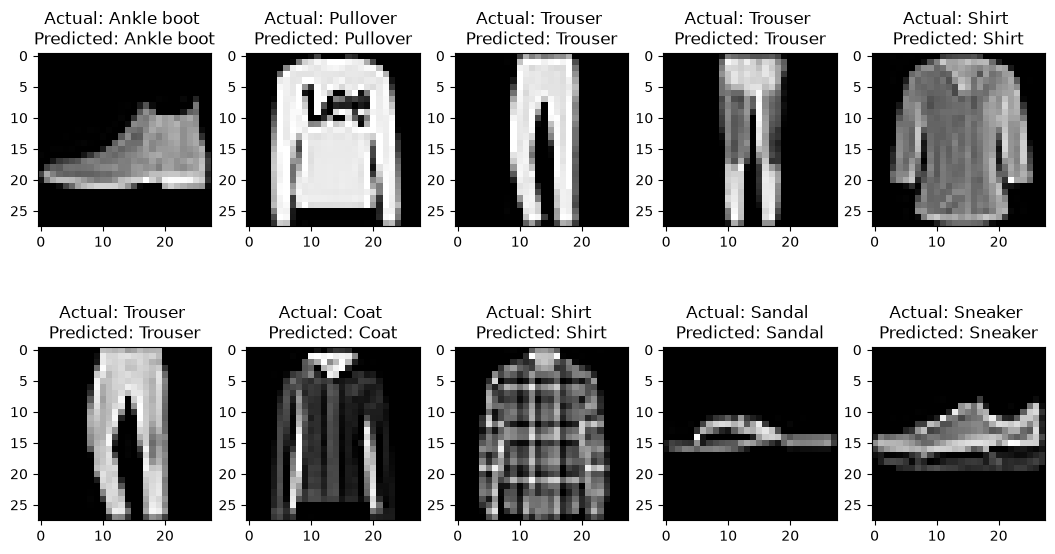

In [40]:
y_pred_proba = model.predict(x_test)
y_pred = np.argmax(y_pred_proba, axis=1)

plt.figure(figsize=(13, 7))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i],cmap="gray")
    plt.title(f"Actual: {class_names[y_test[i]]} \nPredicted: {class_names[y_pred[i]]}")
plt.show()